# 코드 F · 문장·뉴스·평점 — 글자로 된 금융 데이터
**핀테크 데이터 분석 : 실제로 해보는 데이터 분석편 #01**  
원본: [fintech-data/Revolution6](https://github.com/fintech-data/Revolution6) `Loading_Data.ipynb` → 이 폴더의 `original_Loading_Data.ipynb`  
해설 페이지: https://adminmrobo.github.io/fintech_data_analysis/hands_on_01.html

> 코드를 몰라도 괜찮아요. 위에서부터 ▶ 실행 버튼만 차례로 누르면 됩니다.

## 이 코드가 하는 일
숫자가 아니라 **글자(문장·뉴스)와 평점**으로 된 데이터 다섯 가지를 불러옵니다: 금융 문장 감성, 가짜/진짜 뉴스, 종목 이름 유사도, 영화 평점, 넷플릭스 작품 목록.

> 비유: 고객의 손편지·민원 문자·별점 리뷰를 상자째 받아 "몇 통이고 어떤 종류인지"부터 분류하는 일.

큰 파일(뉴스·넷플릭스·영화 정보)은 `.csv.gz`로 줄여 두었고 pandas가 그대로 읽습니다.

In [1]:
import os, io, urllib.request
import pandas as pd
pd.set_option('display.max_columns', 12); pd.set_option('display.width', 120)

# 데이터 위치: 이 폴더의 data/ 에 있으면 그걸 쓰고, 없으면(Colab 등) GitHub에서 바로 읽습니다.
RAW = 'https://raw.githubusercontent.com/adminmrobo/fintech_data_analysis/main/hands_on/01/F_text_and_ratings/data/'
def load(name, **kw):
    local = os.path.join('data', name)
    src = local if os.path.exists(local) else RAW + urllib.parse.quote(name)
    return pd.read_csv(src, low_memory=False, **kw)
print('준비 완료')

준비 완료


In [2]:
data = load('Financial_Sentiment_Analysis.csv', index_col=0)
print(data.shape)
data['Sentiment'].value_counts()

(5842, 2)


Sentiment
neutral     3130
positive    1852
negative     860
Name: count, dtype: int64

In [3]:
print('완전히 같은 문장이 두 번 이상 나온 수:', data['Sentence'].duplicated().sum())
print('문장 평균 단어 수:', round(data['Sentence'].str.split().str.len().mean(), 1))

완전히 같은 문장이 두 번 이상 나온 수: 520
문장 평균 단어 수: 21.0


In [4]:
fake_df = load('News_Fake_and_Real_Fake.csv.gz')
true_df = load('News_Fake_and_Real_True.csv.gz')
print('가짜', fake_df.shape, '/ 진짜', true_df.shape)
print('가짜 뉴스 분류:', fake_df['subject'].unique())
print('진짜 뉴스 분류:', true_df['subject'].unique())

가짜 (23481, 4) / 진짜 (21417, 4)
가짜 뉴스 분류: <StringArray>
['News', 'politics', 'Government News', 'left-news', 'US_News', 'Middle-east']
Length: 6, dtype: str
진짜 뉴스 분류: <StringArray>
['politicsNews', 'worldnews']
Length: 2, dtype: str


In [5]:
train = load('text_similarity_train.csv', index_col=0)
test = load('text_similarity_test.csv', index_col=0)
print(train.shape, test.shape)
train['same_security'].value_counts()

(2142, 5) (516, 3)


same_security
True     1613
False     529
Name: count, dtype: int64

In [6]:
ratings = load('ratings_small.csv')
n_u, n_m = ratings['userId'].nunique(), ratings['movieId'].nunique()
print('사용자', n_u, '/ 영화', n_m, '/ 평점', len(ratings))
print('채워진 비율(%):', round(len(ratings) / (n_u * n_m) * 100, 2))

사용자 671 / 영화 9066 / 평점 100004
채워진 비율(%): 1.64


In [7]:
netflix = load('netflix_list.csv.gz')
print(netflix.shape)
netflix['type'].value_counts().head()

(7008, 19)


type
movie           2923
tvSeries        2199
tvEpisode        785
tvSpecial        391
tvMiniSeries     318
Name: count, dtype: int64

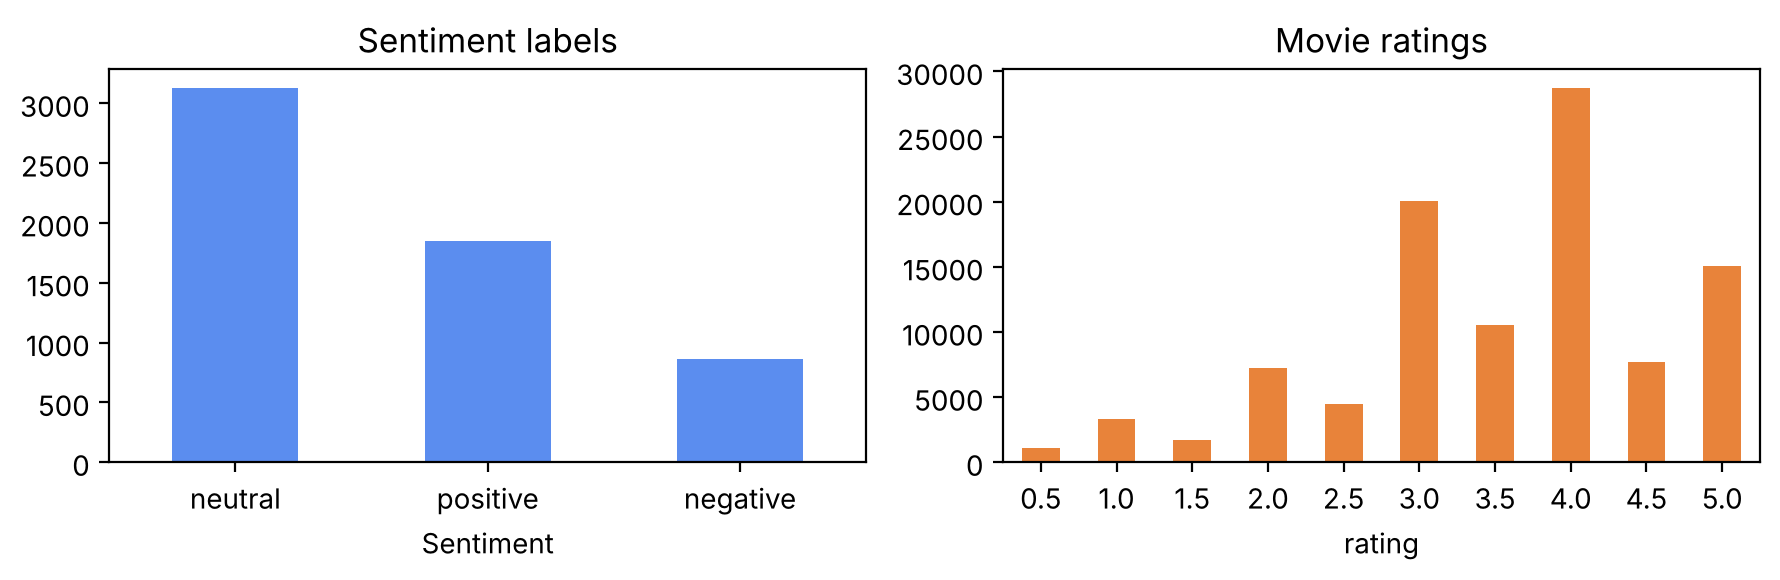

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
data['Sentiment'].value_counts().plot.bar(ax=ax[0], rot=0, color='#5b8def', title='Sentiment labels')
ratings['rating'].value_counts().sort_index().plot.bar(ax=ax[1], rot=0, color='#e8833a', title='Movie ratings')
plt.tight_layout(); plt.show()